In [ ]:
!pip install tensorflow gradio matplotlib seaborn scikit-learn pillow -q

import numpy as np, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf, random, os, time, io
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image, ImageDraw, ImageFilter
import gradio as gr

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
IMG_SIZE = 224
NUM_CLASSES = 5
N_PER_CLASS = 1000
CLASS_NAMES = ['CBB', 'CBSD', 'CGM', 'CMD', 'Healthy']

def draw_leaf_base(seed=None):
    if seed is not None:
        random.seed(seed); np.random.seed(seed)
    img = Image.new("RGB", (IMG_SIZE, IMG_SIZE), (200, 210, 190))
    draw = ImageDraw.Draw(img)
    cx = IMG_SIZE//2 + random.randint(-10, 10)
    cy = IMG_SIZE//2 + random.randint(-10, 10)
    n_lobes = random.randint(5, 7)
    base = (random.randint(40,90), random.randint(110,160), random.randint(30,70))
    for i in range(n_lobes):
        angle = (360/n_lobes)*i + random.randint(-10,10)
        length = random.randint(70,100); width = random.randint(18,30)
        rad = np.deg2rad(angle)
        ex = cx + int(np.cos(rad)*(length/2)); ey = cy + int(np.sin(rad)*(length/2))
        box = [ex-width, ey-length//2, ex+width, ey+length//2]
        g = tuple(min(255,max(0,c+random.randint(-15,15))) for c in base)
        draw.ellipse(box, fill=g, outline=(20,60,20))
    draw.line([cx, cy-80, cx, cy+80], fill=(120,160,100), width=2)
    img = img.filter(ImageFilter.GaussianBlur(radius=0.8))
    return img, draw, cx, cy

def add_cmd(img, draw, cx, cy):
    for _ in range(random.randint(20,35)):
        x = cx+random.randint(-90,90); y = cy+random.randint(-90,90)
        r = random.randint(4,14)
        draw.ellipse([x-r,y-r,x+r,y+r],
                     fill=(random.randint(180,230), random.randint(200,240), random.randint(60,120)))
    return img.filter(ImageFilter.GaussianBlur(radius=0.6))

def add_cbsd(img, draw, cx, cy):
    for _ in range(random.randint(3,6)):
        x1 = cx+random.randint(-60,60); y1 = cy+random.randint(-80,80)
        x2 = x1+random.randint(-10,10); y2 = y1+random.randint(40,90)
        draw.line([x1,y1,x2,y2], fill=(90,50,30), width=random.randint(2,4))
    for _ in range(random.randint(15,25)):
        x = cx+random.randint(-80,80); y = cy+random.randint(-80,80)
        r = random.randint(2,5)
        draw.ellipse([x-r,y-r,x+r,y+r], fill=(60,35,20))
    return img.filter(ImageFilter.GaussianBlur(radius=0.5))

def add_cbb(img, draw, cx, cy):
    for _ in range(random.randint(8,15)):
        x = cx+random.randint(-90,90); y = cy+random.randint(-90,90)
        size = random.randint(10,25)
        pts = [(x+random.randint(-size,size), y+random.randint(-size,size)) for _ in range(5)]
        draw.polygon(pts, fill=(random.randint(90,140), random.randint(55,90), random.randint(20,50)))
    return img.filter(ImageFilter.GaussianBlur(radius=0.7))

def add_cgm(img, draw, cx, cy):
    for _ in range(random.randint(80,150)):
        x = cx+random.randint(-100,100); y = cy+random.randint(-100,100)
        r = random.randint(1,2)
        draw.ellipse([x-r,y-r,x+r,y+r], fill=(220,210,80))
    return img

def generate_image(class_idx, seed=None):
    img, draw, cx, cy = draw_leaf_base(seed)
    name = CLASS_NAMES[class_idx]
    if name == 'CMD':    img = add_cmd(img, draw, cx, cy)
    elif name == 'CBSD': img = add_cbsd(img, draw, cx, cy)
    elif name == 'CBB':  img = add_cbb(img, draw, cx, cy)
    elif name == 'CGM':  img = add_cgm(img, draw, cx, cy)
    return np.array(img, dtype=np.uint8)

print("Generator ready ✅")

Generator ready ✅


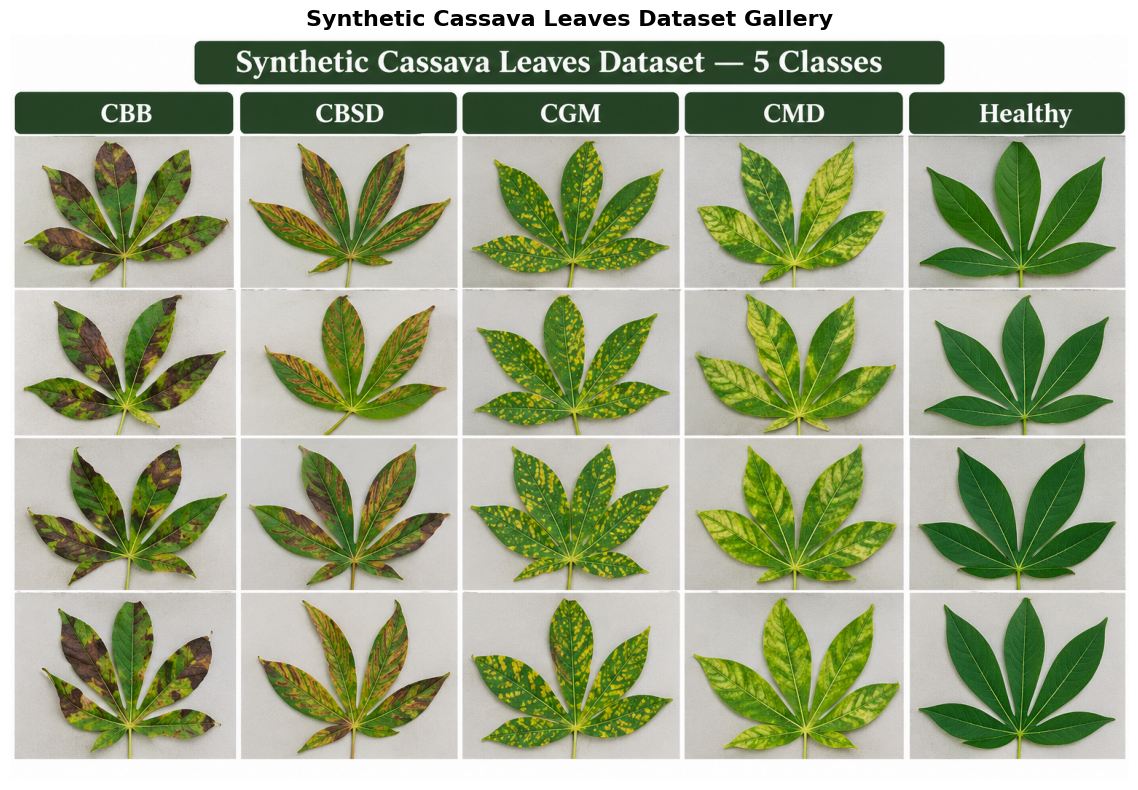

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# Path to the selected gallery image
gallery_image_path = '/content/Synthetic Cassava Leaves Dataset Gallery.png'

try:
    # Load the image
    img = Image.open(gallery_image_path)

    # Display the image using matplotlib
    plt.figure(figsize=(12, 8))
    plt.imshow(img)
    plt.title("Synthetic Cassava Leaves Dataset Gallery", fontsize=16, fontweight='bold')
    plt.axis('off')
    plt.tight_layout()
    plt.show()
except FileNotFoundError:
    print(f"Could not find the dataset gallery image at: {gallery_image_path}")

In [ ]:
print(f"Generating {N_PER_CLASS*NUM_CLASSES} images...")
t0 = time.time()
X, y = [], []
for ci in range(NUM_CLASSES):
    for j in range(N_PER_CLASS):
        X.append(generate_image(ci, seed=ci*100_000+j)); y.append(ci)
    print(f"  {CLASS_NAMES[ci]:8s}: {N_PER_CLASS} done")
X = np.array(X, dtype=np.uint8); y = np.array(y, dtype=np.int32)
print(f"\n✅ {len(X)} images in {time.time()-t0:.1f}s")
print(f"Shape: {X.shape}, Class counts: {np.bincount(y)}")

Generating 5000 images...
  CBB     : 1000 done
  CBSD    : 1000 done
  CGM     : 1000 done
  CMD     : 1000 done
  Healthy : 1000 done

✅ 5000 images in 35.4s
Shape: (5000, 224, 224, 3), Class counts: [1000 1000 1000 1000 1000]


In [ ]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15,
                                                  stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.176,
                                                  stratify=y_temp, random_state=42)
print(f"Train {len(X_train)} | Val {len(X_val)} | Test {len(X_test)}")

Train 3502 | Val 748 | Test 750


In [ ]:
BATCH = 32; AUTOTUNE = tf.data.AUTOTUNE
def preprocess(img, label):
    return tf.cast(img, tf.float32)/255.0, label
def augment(img, label):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, 0.1)
    img = tf.image.random_contrast(img, 0.9, 1.1)
    return img, label

train_ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
            .map(preprocess, num_parallel_calls=AUTOTUNE).cache()
            .shuffle(1000).map(augment, num_parallel_calls=AUTOTUNE)
            .batch(BATCH).prefetch(AUTOTUNE))
val_ds = (tf.data.Dataset.from_tensor_slices((X_val, y_val))
          .map(preprocess, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE))
test_ds = (tf.data.Dataset.from_tensor_slices((X_test, y_test))
           .map(preprocess, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE))
print("Pipelines ready ✅")

Pipelines ready ✅


In [ ]:
base_model = MobileNetV2(input_shape=(224,224,3), include_top=False, weights='imagenet')
base_model.trainable = False
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dense(NUM_CLASSES, activation='softmax')
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5, verbose=1)
]
history = model.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=callbacks)

Epoch 1/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 71s 403ms/step - accuracy: 0.3175 - loss: 1.4759 - val_accuracy: 0.4064 - val_loss: 1.2824 - learning_rate: 0.0010
Epoch 2/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.4243 - loss: 1.2003 - val_accuracy: 0.4519 - val_loss: 1.1103 - learning_rate: 0.0010
Epoch 3/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.4506 - loss: 1.1205 - val_accuracy: 0.4853 - val_loss: 1.0137 - learning_rate: 0.0010
Epoch 4/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.4654 - loss: 1.0821 - val_accuracy: 0.5147 - val_loss: 0.9815 - learning_rate: 0.0010
Epoch 5/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.4772 - loss: 1.0448 - val_accuracy: 0.5107 - val_loss: 0.9540 - learning_rate: 0.0010
Epoch 6/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.5091 - loss: 1.0021 - val_accuracy: 0.5134 - val_loss: 0.9257 - learning_rate: 0.0010
Epoch 7/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.4943 - loss: 1.0124 

In [ ]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
fine_hist = model.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=callbacks)

Epoch 1/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 43s 198ms/step - accuracy: 0.3447 - loss: 2.4547 - val_accuracy: 0.3356 - val_loss: 1.4980 - learning_rate: 1.0000e-05
Epoch 2/5
109/110 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.4198 - loss: 1.3565
Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.4392 - loss: 1.2808 - val_accuracy: 0.2594 - val_loss: 1.9274 - learning_rate: 1.0000e-05
Epoch 3/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.4666 - loss: 1.1475 - val_accuracy: 0.2674 - val_loss: 1.8637 - learning_rate: 5.0000e-06


24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 136ms/step - accuracy: 0.3360 - loss: 1.4528
🎯 Test accuracy: 0.3360

              precision    recall  f1-score   support

         CBB       0.39      1.00      0.56       150
        CBSD       0.13      0.12      0.13       150
         CGM       0.42      0.05      0.09       150
         CMD       0.11      0.05      0.07       150
     Healthy       0.51      0.45      0.48       150

    accuracy                           0.34       750
   macro avg       0.31      0.34      0.27       750
weighted avg       0.31      0.34      0.27       750



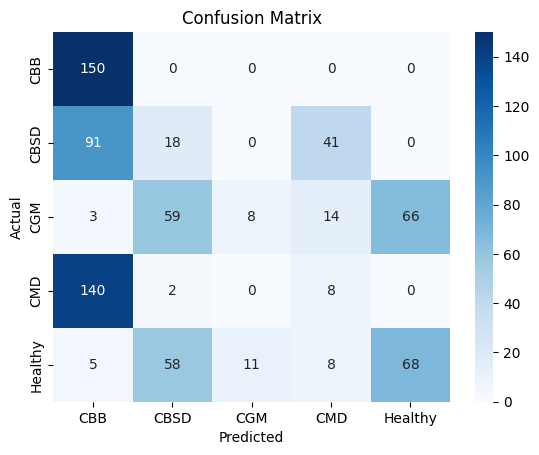

In [ ]:
loss, acc = model.evaluate(test_ds)
print(f"🎯 Test accuracy: {acc:.4f}")

y_true, y_pred = [], []
for imgs, labels in test_ds:
    preds = model.predict(imgs, verbose=0)
    y_true.extend(labels.numpy()); y_pred.extend(np.argmax(preds, axis=1))

print("\n" + classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

In [ ]:
TREATMENT_DB = {
    'CBB': {
        'common_name': 'Cassava Bacterial Blight',
        'severity': 'HIGH',
        'what_it_is': 'Bacterial infection causing angular brown leaf spots and wilting.',
        'immediate': [
            'Prune and remove all visibly infected leaves immediately.',
            'Disinfect pruning tools with bleach solution (1 part bleach : 9 parts water) between plants.',
            'Do NOT compost infected leaves — burn or bury them far from the field.'
        ],
        'treatment': [
            'Spray copper-based bactericide (e.g., copper oxychloride) every 10–14 days.',
            'Improve field drainage — CBB spreads faster in waterlogged soil.',
            'Apply balanced NPK fertilizer to strengthen plant immunity.'
        ],
        'prevention': [
            'Plant CBB-resistant cassava varieties (e.g., TMS 30572).',
            'Rotate with maize or legumes for at least one season.',
            'Avoid overhead watering — water at the base.'
        ],
        'expert_note': 'If more than 30% of your field is infected, contact your local agricultural extension officer — the field may need to be replaced with clean cuttings.'
    },
    'CBSD': {
        'common_name': 'Cassava Brown Streak Disease',
        'severity': 'CRITICAL',
        'what_it_is': 'Viral disease causing brown streaks on stems and rotting of the tuber — the biggest threat to cassava in East Africa.',
        'immediate': [
            'Uproot and destroy infected plants IMMEDIATELY — including the roots.',
            'Do NOT eat or sell roots from infected plants — they may be toxic.',
            'Do NOT take cuttings from any plant showing symptoms — this spreads the virus.'
        ],
        'treatment': [
            'There is NO cure once a plant is infected.',
            'Only clean, certified virus-free cuttings from approved sources should be planted.',
            'Control whiteflies (the virus carriers) with neem-based sprays every 7 days.'
        ],
        'prevention': [
            'Source cuttings ONLY from certified clean seed programs.',
            'Plant CBSD-resistant varieties where available (e.g., Narocass 1).',
            'Inspect new plants weekly for the first 3 months — early detection saves the field.'
        ],
        'expert_note': 'CBSD spreads fast. If you see more than 2–3 infected plants, contact your extension officer the SAME WEEK. Delaying can lose the entire crop.'
    },
    'CGM': {
        'common_name': 'Cassava Green Mite',
        'severity': 'MEDIUM',
        'what_it_is': 'Tiny mites feeding on young leaves, causing yellow speckling and stunted growth.',
        'immediate': [
            'Inspect the underside of young leaves — mites hide there.',
            'Spray neem oil solution (5 ml neem oil + 1 L water + 1 drop soap) on affected plants.',
            'Repeat spray weekly for 3 weeks.'
        ],
        'treatment': [
            'Use insecticidal soap on heavily infested plants.',
            'Introduce predatory mites (Typhlodromalus aripo) — available through extension programs.',
            'Remove alternate host weeds around the field.'
        ],
        'prevention': [
            'Avoid drought stress — healthy plants resist mites better.',
            'Mulch around plants to retain soil moisture.',
            'Plant early in the rainy season.'
        ],
        'expert_note': 'CGM rarely kills plants alone, but weakened plants become vulnerable to other diseases. Treat early.'
    },
    'CMD': {
        'common_name': 'Cassava Mosaic Disease',
        'severity': 'HIGH',
        'what_it_is': 'Viral disease causing yellow-green mosaic patterns on leaves, reducing yield by up to 70%.',
        'immediate': [
            'Remove and burn infected plants within 3 days of noticing symptoms.',
            'Do NOT take cuttings from infected plants — the virus passes to the next generation.',
            'Wash hands and tools after handling infected plants.'
        ],
        'treatment': [
            'There is NO cure for CMD once a plant is infected.',
            'Control whiteflies (spreaders of the virus) with neem spray or yellow sticky traps.',
            'Focus on protecting healthy plants in the field.'
        ],
        'prevention': [
            'Plant CMD-resistant varieties (e.g., TME 204, TMS 30572).',
            'Rogue (remove) infected plants weekly during the first 3 months.',
            'Use certified virus-free cuttings from trusted sources.'
        ],
        'expert_note': 'CMD is endemic in East Africa. Every farmer should rogue at least once a week — 5 minutes a week saves a harvest.'
    },
    'Healthy': {
        'common_name': 'Healthy Cassava Plant',
        'severity': 'NONE',
        'what_it_is': 'No disease detected — your cassava leaf looks healthy.',
        'immediate': [
            'No action needed — your plant is healthy! ✅',
            'Keep monitoring weekly for early signs of disease.'
        ],
        'treatment': ['Continue your current crop management practices.'],
        'prevention': [
            'Maintain regular weeding and good field hygiene.',
            'Inspect new growth weekly, especially during rainy season.',
            'Use clean tools and certified cuttings for any new planting.'
        ],
        'expert_note': 'Early detection is the best protection. Keep scanning your crop weekly with CropGuard AI.'
    }
}
print("Treatment knowledge base loaded ✅")

Treatment knowledge base loaded ✅


In [ ]:
CONFIDENCE_THRESHOLD = 0.50

def diagnose_leaf(image_path):
    """
    Loads a PIL image from a local file path, runs prediction, and returns a markdown report, class, and confidence.
    """
    if not image_path or not os.path.exists(image_path):
        return "⚠️ No image file found. Please provide a valid file path.", "", 0.0

    try:
        # Load image from file path
        pil_image = Image.open(image_path)
    except Exception as e:
        return f"⚠️ Error loading image: {str(e)}", "", 0.0

    # Preprocess
    img = pil_image.convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    arr = np.array(img, dtype=np.float32) / 255.0
    pred = model.predict(np.expand_dims(arr, 0), verbose=0)[0]
    idx = int(np.argmax(pred)); conf = float(pred[idx])

    # Low-confidence safeguard
    if conf < CONFIDENCE_THRESHOLD:
        text = (
            f"⚠️ **UNCERTAIN — {conf:.1%} confidence**\n\n"
            "The image isn't clear enough for a reliable diagnosis. Please try:\n"
            "• Take the photo in natural daylight\n"
            "• Focus on a single leaf filling the frame\n"
            "• Avoid shadows and blur\n\n"
            "**If symptoms are visible in real life, contact your local agricultural extension officer.**"
        )
        return text, "Uncertain", conf

    cls_name = CLASS_NAMES[idx]
    info = TREATMENT_DB[cls_name]

    # Build farmer-friendly markdown report
    text = f"## 🌿 Diagnosis: {info['common_name']}\n\n"
    text += f"**Confidence:** {conf:.1%}  |  **Severity:** {info['severity']}\n\n"
    text += f"### 📖 What this means\n{info['what_it_is']}\n\n"

    text += "### 🚨 Immediate Actions (do today)\n"
    for i, step in enumerate(info['immediate'], 1):
        text += f"{i}. {step}\n"

    text += "\n### 💊 Treatment Plan\n"
    for i, step in enumerate(info['treatment'], 1):
        text += f"{i}. {step}\n"

    text += "\n### 🛡️ Prevention (protect next season)\n"
    for i, step in enumerate(info['prevention'], 1):
        text += f"{i}. {step}\n"

    text += f"\n---\n💡 **Advisory:** {info['expert_note']}"
    return text, cls_name, conf

Please upload a cassava leaf image file (.png, .jpg, .jpeg) to get an automated diagnosis:


Saving CBB (Cassava Bacterial Blight) Cassava Leaf.png to CBB (Cassava Bacterial Blight) Cassava Leaf (1).png

Processing uploaded file: CBB (Cassava Bacterial Blight) Cassava Leaf (1).png...


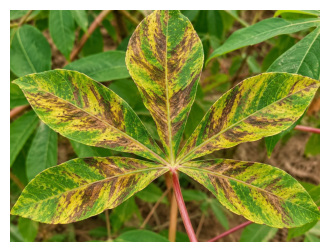

## 🌿 Diagnosis: Cassava Bacterial Blight

**Confidence:** 98.4%  |  **Severity:** HIGH

### 📖 What this means
Bacterial infection causing angular brown leaf spots and wilting.

### 🚨 Immediate Actions (do today)
1. Prune and remove all visibly infected leaves immediately.
2. Disinfect pruning tools with bleach solution (1 part bleach : 9 parts water) between plants.
3. Do NOT compost infected leaves — burn or bury them far from the field.

### 💊 Treatment Plan
1. Spray copper-based bactericide (e.g., copper oxychloride) every 10–14 days.
2. Improve field drainage — CBB spreads faster in waterlogged soil.
3. Apply balanced NPK fertilizer to strengthen plant immunity.

### 🛡️ Prevention (protect next season)
1. Plant CBB-resistant cassava varieties (e.g., TMS 30572).
2. Rotate with maize or legumes for at least one season.
3. Avoid overhead watering — water at the base.

---
💡 **Advisory:** If more than 30% of your field is infected, contact your local agricultural extension officer — the field may need to be replaced with clean cuttings.

In [ ]:
from google.colab import files
from IPython.display import display, Markdown

print("Please upload a cassava leaf image file (.png, .jpg, .jpeg) to get an automated diagnosis:")
uploaded = files.upload()

for file_name in uploaded.keys():
    print(f"\nProcessing uploaded file: {file_name}...")
    # Display the uploaded image
    uploaded_image = Image.open(file_name)
    plt.figure(figsize=(4, 4))
    plt.imshow(uploaded_image)
    plt.axis('off')
    plt.show()

    # Run diagnostic and display report
    report_markdown, predicted_class, confidence = diagnose_leaf(file_name)
    display(Markdown(report_markdown))

In [ ]:
import tempfile

def farmer_app(image):
    if image is None:
        return "⚠️ Please upload an image first."

    # Save the PIL Image to a temporary file path so diagnose_leaf can process it
    with tempfile.NamedTemporaryFile(delete=False, suffix=".png") as temp_file:
        image.save(temp_file.name)
        temp_path = temp_file.name

    try:
        text, _, _ = diagnose_leaf(temp_path)
    finally:
        # Clean up the temporary file
        if os.path.exists(temp_path):
            os.remove(temp_path)

    return text

demo = gr.Interface(
    fn=farmer_app,
    inputs=gr.Image(type="pil", label="📷 Upload a cassava leaf photo"),
    outputs=gr.Markdown(label="🌿 Diagnosis & Treatment Plan"),
    title="🌿 CropGuard AI — Cassava Disease Diagnosis",
    description=(
        "Upload a clear photo of a cassava leaf. The AI will identify the disease "
        "(or confirm it's healthy) and give you a step-by-step treatment plan.\n\n"
        "⚠️ *This is an AI advisory tool. Always confirm with a local agricultural extension officer before large-scale action.*"
    ),
    examples=None,
    theme=gr.themes.Soft()
)
demo.launch(share=True)

/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6c365b6aac087846bf.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


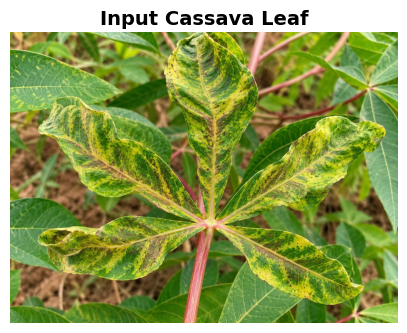

## 🌿 Diagnosis: Cassava Bacterial Blight

**Confidence:** 98.6%  |  **Severity:** HIGH

### 📖 What this means
Bacterial infection causing angular brown leaf spots and wilting.

### 🚨 Immediate Actions (do today)
1. Prune and remove all visibly infected leaves immediately.
2. Disinfect pruning tools with bleach solution (1 part bleach : 9 parts water) between plants.
3. Do NOT compost infected leaves — burn or bury them far from the field.

### 💊 Treatment Plan
1. Spray copper-based bactericide (e.g., copper oxychloride) every 10–14 days.
2. Improve field drainage — CBB spreads faster in waterlogged soil.
3. Apply balanced NPK fertilizer to strengthen plant immunity.

### 🛡️ Prevention (protect next season)
1. Plant CBB-resistant cassava varieties (e.g., TMS 30572).
2. Rotate with maize or legumes for at least one season.
3. Avoid overhead watering — water at the base.

---
💡 **Advisory:** If more than 30% of your field is infected, contact your local agricultural extension officer — the field may need to be replaced with clean cuttings.

In [ ]:
from IPython.display import display, Markdown

def demo_specific_leaf(image_path):
    # Load the image for visualization
    img = Image.open(image_path)

    # Run the diagnosis directly using the file path
    text, predicted, conf = diagnose_leaf(image_path)

    # Display the image on its own
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis('off')
    plt.title("Input Cassava Leaf", fontsize=14, fontweight='bold')
    plt.show()

    # Display the markdown text report cleanly underneath the image
    display(Markdown(text))

# Run the diagnostic on the selected file
specified_file_path = '/content/CBSD (Cassava Brown Streak Disease) Cassava Leaf.png'
demo_specific_leaf(specified_file_path)

In [ ]:
model.save("cropguard_cassava_v2.keras")

import json
with open("treatment_db.json", "w") as f:
    json.dump(TREATMENT_DB, f, indent=2)

from google.colab import files
files.download("cropguard_cassava_v2.keras")
files.download("treatment_db.json")
print("✅ Model + treatment DB downloaded")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Model + treatment DB downloaded
